# Week 07：决策树

## 决策树分类算法——基于企鹅特征的物种分类

### 1. 实验目的

本实验使用 Palmer Penguins 数据集完成企鹅物种多分类任务，学习并实践决策树（Decision Tree）分类算法。

主要实验内容：

1. 理解决策树分类的基本原理；
2. 理解 Gini 不纯度等节点划分指标；
3. 使用决策树完成多分类任务；
4. 分析树深度对模型性能的影响；
5. 使用 Accuracy、混淆矩阵和分类报告评价模型；
6. 对决策树结构进行可视化；
7. 分析决策树过拟合现象以及树深度的作用。

### 2. 数据集加载与初步分析

本实验使用 Palmer Penguins 数据集。该数据集记录了不同企鹅个体的身体特征以及物种类别，可用于多分类任务。

首先加载数据集，并查看数据的基本结构。

In [2]:
import pandas as pd

# 从本地读取数据集
df = pd.read_csv("penguins.csv")

print("数据集形状：", df.shape)

print("\n前5条数据：")
display(df.head())

print("\n数据基本信息：")
df.info()

数据集形状： (344, 7)

前5条数据：


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,MALE
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,FEMALE
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,FEMALE
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,FEMALE



数据基本信息：
<class 'pandas.DataFrame'>
RangeIndex: 344 entries, 0 to 343
Data columns (total 7 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   species            344 non-null    str    
 1   island             344 non-null    str    
 2   bill_length_mm     342 non-null    float64
 3   bill_depth_mm      342 non-null    float64
 4   flipper_length_mm  342 non-null    float64
 5   body_mass_g        342 non-null    float64
 6   sex                333 non-null    str    
dtypes: float64(4), str(3)
memory usage: 18.9 KB


### 3. 数据探索与缺失值分析

在训练决策树模型之前，首先对数据集进行探索，查看目标类别的分布情况以及各个特征的缺失情况，为后续的数据预处理提供依据。

In [3]:
# 查看各物种的样本数量
print("各物种样本数量：")
print(df["species"].value_counts())

print("\n各物种样本比例：")
print(df["species"].value_counts(normalize=True))

# 查看缺失值
print("\n各字段缺失值数量：")
print(df.isnull().sum())

# 查看重复数据
print("\n重复记录数量：", df.duplicated().sum())

各物种样本数量：
species
Adelie       152
Gentoo       124
Chinstrap     68
Name: count, dtype: int64

各物种样本比例：
species
Adelie       0.441860
Gentoo       0.360465
Chinstrap    0.197674
Name: proportion, dtype: float64

各字段缺失值数量：
species               0
island                0
bill_length_mm        2
bill_depth_mm         2
flipper_length_mm     2
body_mass_g           2
sex                  11
dtype: int64

重复记录数量： 0


### 4. 数据预处理

数据集中部分特征存在少量缺失值。由于缺失样本数量相对于整个数据集较少，本实验直接删除包含缺失值的样本。

同时，`island` 和 `sex` 属于类别型特征，不能直接输入 sklearn 的决策树模型，因此需要将其转换为数值形式。

In [4]:
# 删除包含缺失值的样本
df_clean = df.dropna().copy()

print("原始数据集大小：", df.shape)
print("删除缺失值后的数据集大小：", df_clean.shape)
print("删除的样本数量：", len(df) - len(df_clean))

print("\n处理后的缺失值数量：")
print(df_clean.isnull().sum())

print("\n处理后的物种分布：")
print(df_clean["species"].value_counts())

原始数据集大小： (344, 7)
删除缺失值后的数据集大小： (333, 7)
删除的样本数量： 11

处理后的缺失值数量：
species              0
island               0
bill_length_mm       0
bill_depth_mm        0
flipper_length_mm    0
body_mass_g          0
sex                  0
dtype: int64

处理后的物种分布：
species
Adelie       146
Gentoo       119
Chinstrap     68
Name: count, dtype: int64


### 5. 特征与标签处理

本实验将 `species` 作为预测目标，其余字段作为输入特征。

由于 `island` 和 `sex` 属于类别型特征，使用 One-Hot Encoding 将其转换为数值特征。决策树通过特征阈值进行划分，对不同特征的数值尺度不敏感，因此本实验不进行标准化处理。

In [5]:
# 分离特征和标签
X = df_clean.drop(columns=["species"])
y = df_clean["species"]

# 对类别特征进行独热编码
X = pd.get_dummies(X, columns=["island", "sex"], dtype=int)

print("处理后的特征维度：", X.shape)

print("\n特征名称：")
print(X.columns.tolist())

print("\n前5条特征数据：")
display(X.head())

print("\n标签前5条：")
print(y.head())

处理后的特征维度： (333, 9)

特征名称：
['bill_length_mm', 'bill_depth_mm', 'flipper_length_mm', 'body_mass_g', 'island_Biscoe', 'island_Dream', 'island_Torgersen', 'sex_FEMALE', 'sex_MALE']

前5条特征数据：


,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,island_Biscoe,island_Dream,island_Torgersen,sex_FEMALE,sex_MALE
0,39.1,18.7,181.0,3750.0,0,0,1,0,1
1,39.5,17.4,186.0,3800.0,0,0,1,1,0
2,40.3,18.0,195.0,3250.0,0,0,1,1,0
4,36.7,19.3,193.0,3450.0,0,0,1,1,0
5,39.3,20.6,190.0,3650.0,0,0,1,0,1



标签前5条：
0    Adelie
1    Adelie
2    Adelie
4    Adelie
5    Adelie
Name: species, dtype: str


### 6. 划分训练集和测试集

将处理后的数据按照 80% : 20% 的比例划分为训练集和测试集。

为了保证训练集和测试集中不同企鹅物种的类别比例基本一致，使用 `stratify=y` 进行分层抽样，并设置固定的 `random_state=42`，保证实验结果可以复现。

In [6]:
from sklearn.model_selection import train_test_split

# 按 80% : 20% 划分训练集和测试集
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("训练集特征维度：", X_train.shape)
print("测试集特征维度：", X_test.shape)

print("\n训练集类别分布：")
print(y_train.value_counts())

print("\n测试集类别分布：")
print(y_test.value_counts())

训练集特征维度： (266, 9)
测试集特征维度： (67, 9)

训练集类别分布：
species
Adelie       117
Gentoo        95
Chinstrap     54
Name: count, dtype: int64

测试集类别分布：
species
Adelie       29
Gentoo       24
Chinstrap    14
Name: count, dtype: int64


### 7. Gini 不纯度

CART 分类决策树通常使用 Gini 不纯度（Gini Impurity）衡量一个节点中样本类别的混杂程度。

Gini 值越小，说明节点中的样本类别越纯；当节点中的所有样本都属于同一个类别时，Gini 值为 0。

本实验首先手动实现 Gini 不纯度的计算，以理解决策树选择划分特征的基本原理。

In [7]:
def gini(y):
    # 计算每个类别所占的比例
    probabilities = y.value_counts(normalize=True)

    # Gini = 1 - 各类别概率平方和
    return 1 - sum(probabilities ** 2)


# 计算整个训练集的 Gini
train_gini = gini(y_train)

print("训练集 Gini 不纯度：", train_gini)

# 构造一个完全纯净的节点进行测试
pure_node = pd.Series(["Adelie", "Adelie", "Adelie", "Adelie"])

print("纯节点 Gini 不纯度：", gini(pure_node))

训练集 Gini 不纯度： 0.6377692351178699
纯节点 Gini 不纯度： 0.0


### 8. CART 决策树模型训练

使用 sklearn 的 `DecisionTreeClassifier` 构建分类决策树。

本实验采用 `criterion="gini"`，即使用 Gini 不纯度作为节点划分标准。首先不限制树的最大深度，让决策树根据训练数据充分生长，之后再分析树深度对模型性能和过拟合的影响。

In [8]:
from sklearn.tree import DecisionTreeClassifier

# 创建 CART 决策树分类器
dt_model = DecisionTreeClassifier(
    criterion="gini",
    random_state=42
)

# 训练模型
dt_model.fit(X_train, y_train)

print("决策树训练完成！")
print("决策树深度：", dt_model.get_depth())
print("叶子节点数量：", dt_model.get_n_leaves())

# 查看根节点使用的特征
root_feature_index = dt_model.tree_.feature[0]
root_feature = X.columns[root_feature_index]
root_threshold = dt_model.tree_.threshold[0]

print("\n根节点划分特征：", root_feature)
print("根节点划分阈值：", root_threshold)

决策树训练完成！
决策树深度： 5
叶子节点数量： 12

根节点划分特征： flipper_length_mm
根节点划分阈值： 207.5


### 9. 模型性能评价

使用训练好的决策树分别对训练集和测试集进行预测，并通过 Accuracy、混淆矩阵和分类报告评价模型性能。

同时比较训练集准确率和测试集准确率，初步分析完全生长的决策树是否存在过拟合现象。

In [9]:
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# 分别预测训练集和测试集
y_train_pred = dt_model.predict(X_train)
y_test_pred = dt_model.predict(X_test)

# 计算准确率
train_accuracy = accuracy_score(y_train, y_train_pred)
test_accuracy = accuracy_score(y_test, y_test_pred)

print("训练集准确率：{:.2%}".format(train_accuracy))
print("测试集准确率：{:.2%}".format(test_accuracy))

print("\n测试集混淆矩阵：")
print(confusion_matrix(
    y_test,
    y_test_pred,
    labels=["Adelie", "Chinstrap", "Gentoo"]
))

print("\n测试集分类报告：")
print(classification_report(y_test, y_test_pred))

训练集准确率：100.00%
测试集准确率：92.54%

测试集混淆矩阵：
[[26  3  0]
 [ 0 14  0]
 [ 2  0 22]]

测试集分类报告：
              precision    recall  f1-score   support

      Adelie       0.93      0.90      0.91        29
   Chinstrap       0.82      1.00      0.90        14
      Gentoo       1.00      0.92      0.96        24

    accuracy                           0.93        67
   macro avg       0.92      0.94      0.92        67
weighted avg       0.93      0.93      0.93        67



### 10. 决策树结构可视化

为了直观观察模型的决策过程，对训练得到的决策树进行可视化。

通过决策树结构可以观察每个节点所选择的划分特征、划分阈值、Gini 不纯度、样本数量以及类别分布，从而增强模型的可解释性。

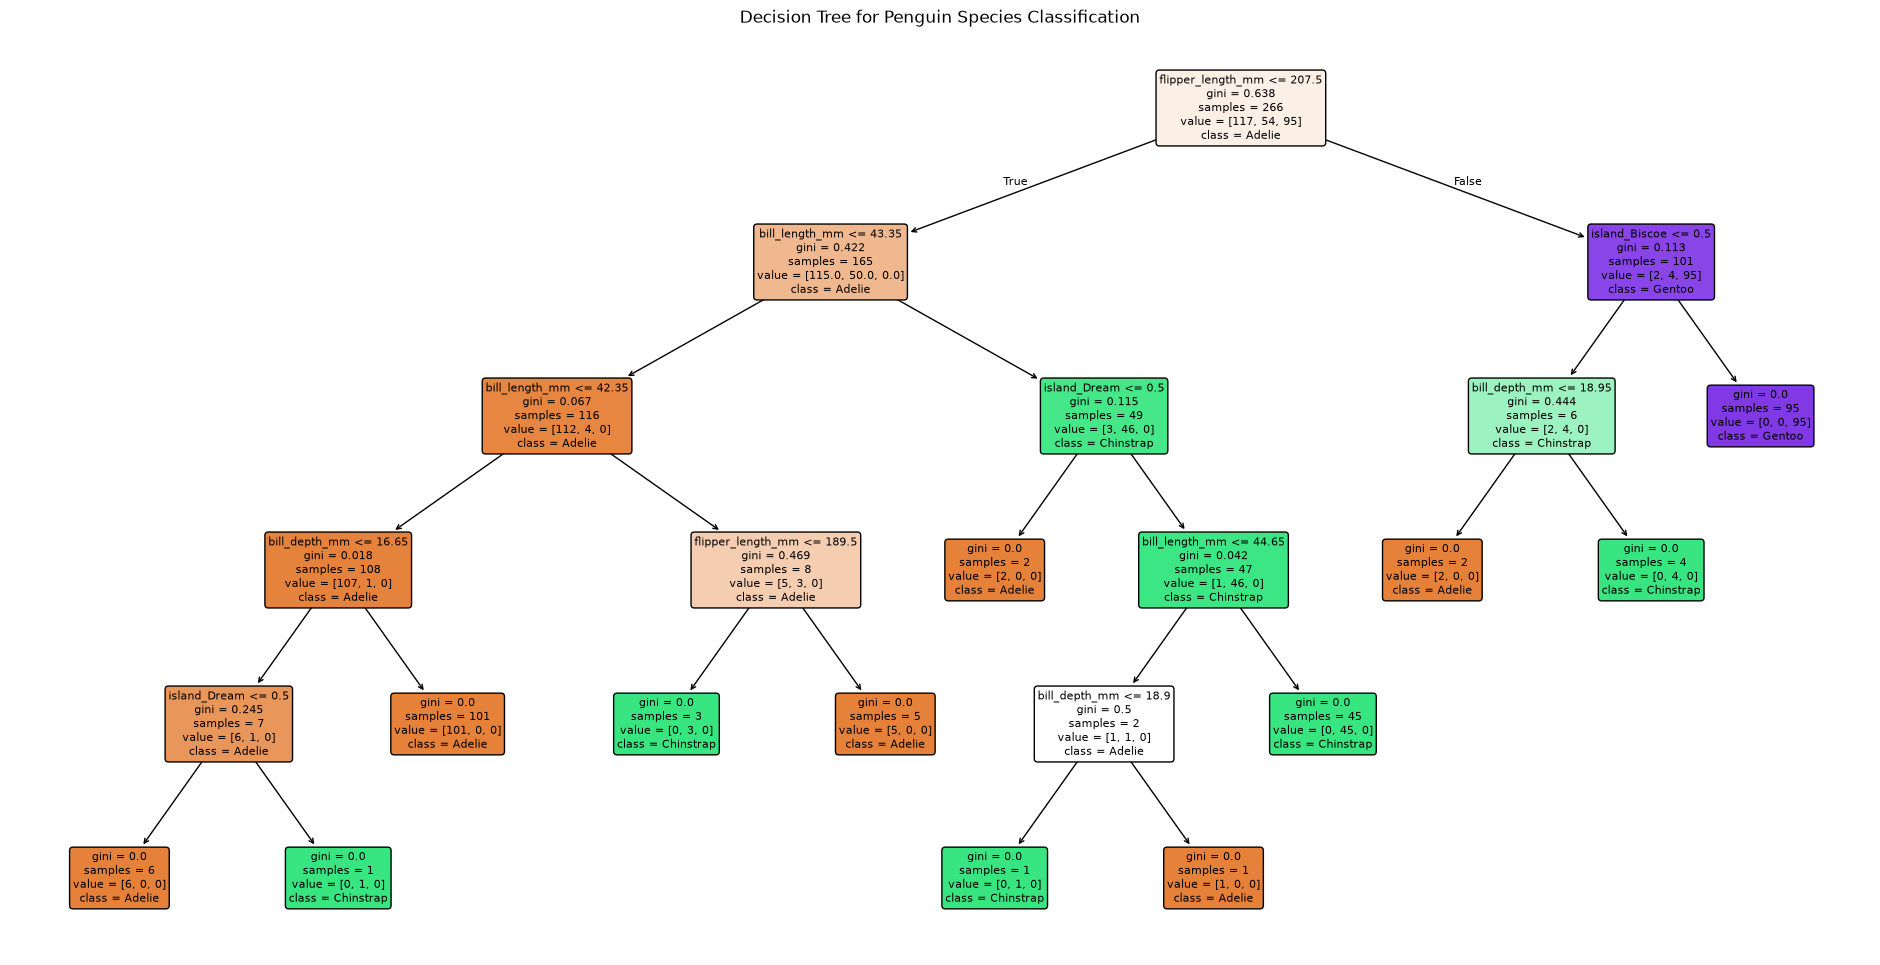

In [12]:
import matplotlib.pyplot as plt
from sklearn.tree import plot_tree

plt.figure(figsize=(24, 12))

plot_tree(
    dt_model,
    feature_names=X.columns,
    class_names=dt_model.classes_,
    filled=True,
    rounded=True,
    fontsize=8
)

plt.title("Decision Tree for Penguin Species Classification")
plt.show()

### 11. 树深度对模型性能的影响

决策树如果深度过小，可能无法充分学习数据中的规律，从而产生欠拟合；如果深度过大，则可能学习训练数据中的噪声和个别样本特征，从而产生过拟合。

因此，本实验设置不同的 `max_depth`，分别计算训练集和测试集准确率，分析树深度对模型性能的影响。

In [13]:
train_accuracies = []
test_accuracies = []

depths = range(1, 11)

for depth in depths:
    model = DecisionTreeClassifier(
        criterion="gini",
        max_depth=depth,
        random_state=42
    )

    model.fit(X_train, y_train)

    train_acc = accuracy_score(
        y_train,
        model.predict(X_train)
    )

    test_acc = accuracy_score(
        y_test,
        model.predict(X_test)
    )

    train_accuracies.append(train_acc)
    test_accuracies.append(test_acc)

    print(
        f"max_depth={depth}: "
        f"训练集准确率={train_acc:.2%}, "
        f"测试集准确率={test_acc:.2%}"
    )

max_depth=1: 训练集准确率=78.95%, 测试集准确率=76.12%
max_depth=2: 训练集准确率=96.62%, 测试集准确率=94.03%
max_depth=3: 训练集准确率=98.12%, 测试集准确率=95.52%
max_depth=4: 训练集准确率=99.25%, 测试集准确率=97.01%
max_depth=5: 训练集准确率=100.00%, 测试集准确率=92.54%
max_depth=6: 训练集准确率=100.00%, 测试集准确率=92.54%
max_depth=7: 训练集准确率=100.00%, 测试集准确率=92.54%
max_depth=8: 训练集准确率=100.00%, 测试集准确率=92.54%
max_depth=9: 训练集准确率=100.00%, 测试集准确率=92.54%
max_depth=10: 训练集准确率=100.00%, 测试集准确率=92.54%


### 12. 不同树深度的性能对比

为了更加直观地观察树深度对模型性能的影响，将不同 `max_depth` 下的训练集准确率和测试集准确率绘制成折线图。

通过比较两条曲线，可以观察决策树从欠拟合到较优状态，再到过拟合的变化过程。

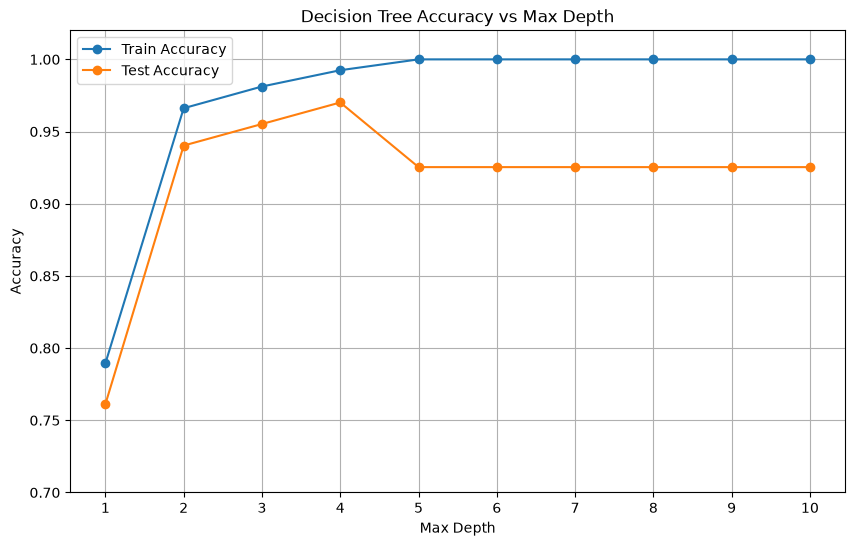

In [14]:
plt.figure(figsize=(10, 6))

plt.plot(
    list(depths),
    train_accuracies,
    marker="o",
    label="Train Accuracy"
)

plt.plot(
    list(depths),
    test_accuracies,
    marker="o",
    label="Test Accuracy"
)

plt.xlabel("Max Depth")
plt.ylabel("Accuracy")
plt.title("Decision Tree Accuracy vs Max Depth")

plt.xticks(list(depths))
plt.ylim(0.7, 1.02)

plt.grid(True)
plt.legend()

plt.show()

### 13. 最终模型训练与评价

根据不同树深度的实验结果，当 `max_depth=4` 时，模型在当前测试集上取得了最高的准确率。

因此，本实验选择 `max_depth=4` 重新训练决策树，并对最终模型进行性能评价。

In [15]:
# 使用 max_depth=4 训练最终模型
final_model = DecisionTreeClassifier(
    criterion="gini",
    max_depth=4,
    random_state=42
)

final_model.fit(X_train, y_train)

# 预测
y_train_final = final_model.predict(X_train)
y_test_final = final_model.predict(X_test)

# 准确率
final_train_acc = accuracy_score(y_train, y_train_final)
final_test_acc = accuracy_score(y_test, y_test_final)

print("最终模型训练集准确率：{:.2%}".format(final_train_acc))
print("最终模型测试集准确率：{:.2%}".format(final_test_acc))

print("\n最终模型混淆矩阵：")
print(
    confusion_matrix(
        y_test,
        y_test_final,
        labels=["Adelie", "Chinstrap", "Gentoo"]
    )
)

print("\n最终模型分类报告：")
print(classification_report(y_test, y_test_final))

最终模型训练集准确率：99.25%
最终模型测试集准确率：97.01%

最终模型混淆矩阵：
[[29  0  0]
 [ 0 14  0]
 [ 2  0 22]]

最终模型分类报告：
              precision    recall  f1-score   support

      Adelie       0.94      1.00      0.97        29
   Chinstrap       1.00      1.00      1.00        14
      Gentoo       1.00      0.92      0.96        24

    accuracy                           0.97        67
   macro avg       0.98      0.97      0.97        67
weighted avg       0.97      0.97      0.97        67



### 14. 特征重要性分析

决策树在训练过程中会根据各个特征对节点不纯度的降低程度计算特征重要性。

特征重要性越高，说明该特征在当前决策树的分类过程中发挥的作用越大。通过分析特征重要性，可以进一步理解模型进行企鹅物种分类时主要依赖哪些特征。

In [16]:
# 获取特征重要性
feature_importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": final_model.feature_importances_
})

# 按重要性从高到低排序
feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

print("特征重要性：")
display(feature_importance)

特征重要性：


,Feature,Importance
2,flipper_length_mm,0.530180
0,bill_length_mm,0.355176
4,island_Biscoe,0.052589
7,sex_FEMALE,0.022464
5,island_Dream,0.022016
1,bill_depth_mm,0.017575
3,body_mass_g,0.000000
6,island_Torgersen,0.000000
8,sex_MALE,0.000000


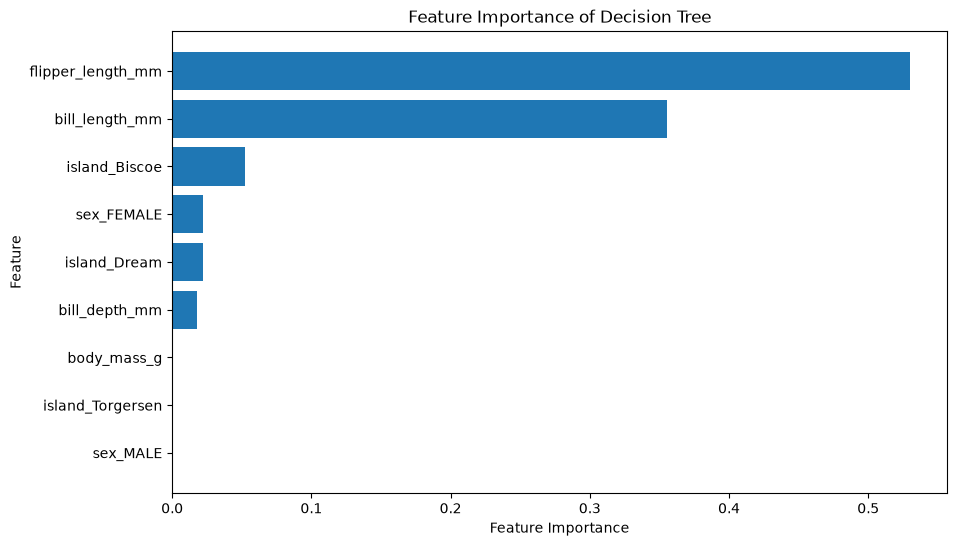

In [17]:
plt.figure(figsize=(10, 6))

plt.barh(
    feature_importance["Feature"],
    feature_importance["Importance"]
)

plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.title("Feature Importance of Decision Tree")

plt.gca().invert_yaxis()
plt.show()

### 15. 最终决策树可视化

对限制最大深度后的最终决策树进行可视化。

与完全生长的决策树相比，限制 `max_depth=4` 可以减少过度复杂的分支，使模型结构更加简单，同时在当前测试集上获得了更好的分类性能。

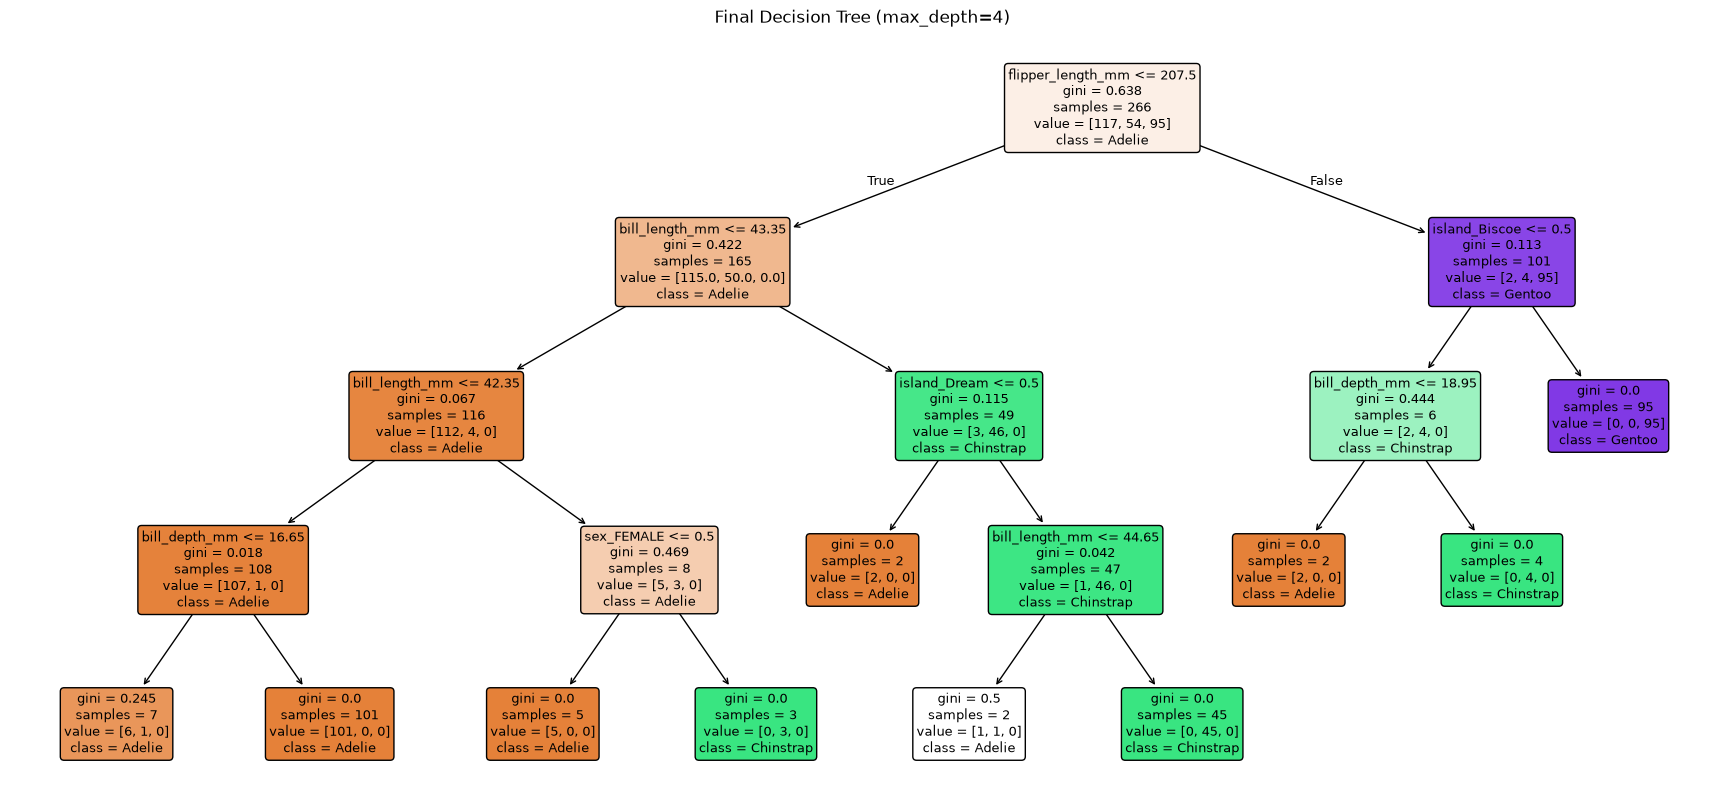

In [18]:
plt.figure(figsize=(22, 10))

plot_tree(
    final_model,
    feature_names=X.columns,
    class_names=final_model.classes_,
    filled=True,
    rounded=True,
    fontsize=9
)

plt.title("Final Decision Tree (max_depth=4)")
plt.show()

### 16. 实验结果分析

本实验使用 Palmer Penguins 数据集构建决策树模型，对 Adelie、Chinstrap 和 Gentoo 三种企鹅进行分类。

实验首先使用 Gini 不纯度作为 CART 决策树的节点划分准则。未限制树深度时，模型的训练集准确率达到 100.00%，测试集准确率为 92.54%，说明模型能够完全拟合训练数据，但存在一定的过拟合倾向。

进一步比较不同 `max_depth` 后发现，当树深度从 1 增加到 4 时，模型的训练集和测试集性能均逐渐提高。其中 `max_depth=4` 时，训练集准确率为 99.25%，测试集准确率达到 97.01%，为本次实验所测试深度中的最高结果。当树深度增加到 5 及以上时，训练集准确率达到 100.00%，但测试集准确率下降至 92.54%，体现出决策树复杂度过高所带来的过拟合现象。

最终选择 `max_depth=4` 的决策树。在 67 个测试样本中，仅有 2 个 Gentoo 样本被误分类为 Adelie，Adelie 和 Chinstrap 测试样本均被正确识别。

特征重要性分析表明，`flipper_length_mm` 和 `bill_length_mm` 是当前模型中最重要的两个特征，重要性分别约为 53.02% 和 35.52%，说明鳍肢长度和喙长度在当前决策树的企鹅物种分类过程中发挥了主要作用。

通过本实验进一步理解了 Gini 不纯度、树深度、决策树可视化和特征重要性等概念，并观察到了模型复杂度与欠拟合、过拟合之间的关系。